# Logistic Regression - Claimants prediction

### 1. Business Undestanding

In [1]:
#output
# Claimants hire an attornoy or not 
# understand which type of customers are more likely to do 


### 2. Data Collection

#### 2.1. Import nesessary library and dataset

In [2]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import pickle

claimants_data =pd.read_csv('claimants.csv')

### 3. Data Understanding

#### 3.1 perform Initial investigation on the data

In [3]:
# shape 
claimants_data.shape
print(claimants_data.shape)


# Null check
claimants_data.isna().sum()
print(claimants_data.isna().sum())

# data types
claimants_data.dtypes
print(claimants_data.dtypes)

(1340, 7)
CASENUM       0
ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64
CASENUM       int64
ATTORNEY      int64
CLMSEX      float64
CLMINSUR    float64
SEATBELT    float64
CLMAGE      float64
LOSS        float64
dtype: object


### 4. Data preparation

#### 4.1 Data Cleaning

In [4]:
claimants_data.dropna(inplace = True)

In [5]:
# duplicates check 
claimants_data.duplicated().unique()
print(claimants_data.duplicated().unique()) 

# describe
claimants_data.describe()

[False]


,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
count,1096.000000,1096.000000,1096.000000,1096.000000,1096.000000,1096.000000,1096.000000
mean,11244.278285,0.472628,0.564781,0.904197,0.018248,28.587591,3.856578
std,9425.386224,0.499478,0.496012,0.294455,0.133909,20.392621,10.473239
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4502.750000,0.000000,0.000000,1.000000,0.000000,9.000000,0.440000
50%,8730.500000,0.000000,1.000000,1.000000,0.000000,30.000000,1.311000
75%,16013.000000,1.000000,1.000000,1.000000,0.000000,43.000000,3.910500
max,34153.000000,1.000000,1.000000,1.000000,1.000000,95.000000,173.604000


#### 4.2 Input and output features

In [6]:
x = claimants_data.iloc[:,2:] #input features 
x

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0.0,1.0,0.0,50.0,34.940
1,1.0,0.0,0.0,18.0,0.891
2,0.0,1.0,0.0,5.0,0.330
3,0.0,1.0,1.0,31.0,0.037
4,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...
1334,1.0,1.0,0.0,16.0,0.060
1336,1.0,1.0,0.0,46.0,3.705
1337,1.0,1.0,0.0,39.0,0.099
1338,1.0,0.0,0.0,8.0,3.177


In [7]:
claimants_data.iloc[:,1]

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64

In [8]:
y = claimants_data['ATTORNEY']
y

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64

### 5. Model Building

In [9]:
X_train, X_test, y_train, y_test = train_test_split(x,y,test_size=0.20,
                                                    shuffle=True,random_state=39)

In [10]:
logistic_model = LogisticRegression()

### 6. Model training

In [11]:
logistic_model.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


### 7. Model testing

##### Training data

In [12]:
y_pred_train = logistic_model.predict(X_train)

##### Testing data

In [13]:
y_pred_test = logistic_model.predict(X_test)

### 8. Model Evaluation

In [29]:
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score,roc_curve,roc_auc_score

##### 8.1 Evaluation metrics for Training data

In [15]:
print(confusion_matrix(y_train,y_pred_train))

[[302 155]
 [ 99 320]]


In [16]:
print(classification_report(y_train,y_pred_train))

              precision    recall  f1-score   support

           0       0.75      0.66      0.70       457
           1       0.67      0.76      0.72       419

    accuracy                           0.71       876
   macro avg       0.71      0.71      0.71       876
weighted avg       0.72      0.71      0.71       876



In [17]:
accuracy_score(y_train,y_pred_train)

0.7100456621004566

##### ROC Curve - Receiver Operating Characteristics
AUC - Area Under this Curve

0.7122773301024112


Text(0, 0.5, 'True Positive Rate')

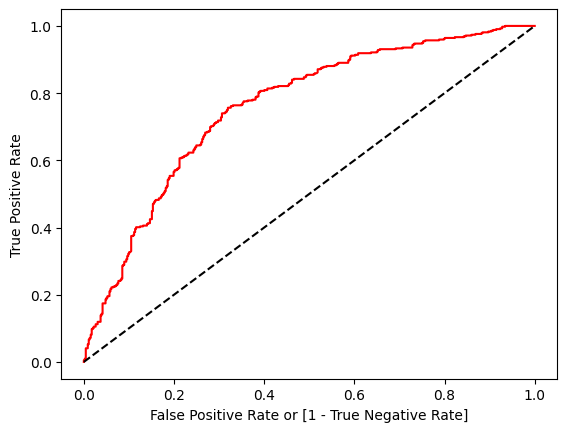

In [30]:
fpr, tpr, thresholds = roc_curve(y_train, logistic_model.predict_proba (X_train)[:,1])

auc = roc_auc_score(y_train,y_pred_train)
print(auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='logit model ( area  = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

##### 8.1 Evaluation metrics for  Test data

In [18]:
print(confusion_matrix(y_test,y_pred_test))

[[78 43]
 [24 75]]


In [19]:
print(classification_report(y_test,y_pred_test))

              precision    recall  f1-score   support

           0       0.76      0.64      0.70       121
           1       0.64      0.76      0.69        99

    accuracy                           0.70       220
   macro avg       0.70      0.70      0.70       220
weighted avg       0.71      0.70      0.70       220



In [20]:
accuracy_score(y_test,y_pred_test)

0.6954545454545454

##### ROC Curve - Receiver Operating Characteristics
AUC - Area Under this Curve

0.7011019283746557


Text(0, 0.5, 'True Positive Rate')

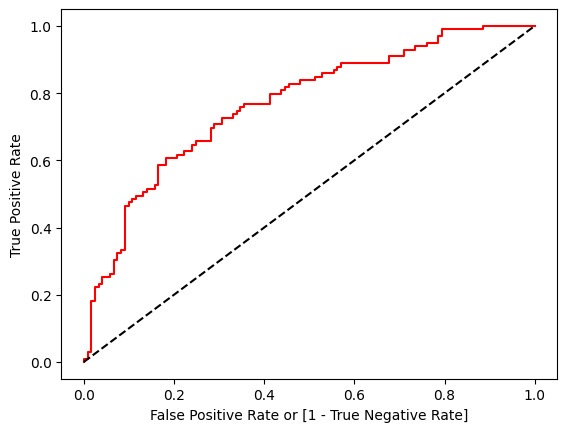

In [53]:
fpr, tpr, thresholds = roc_curve(y_test, logistic_model.predict_proba(X_test)[:,1])

auc = roc_auc_score(y_test,y_pred_test)
print(auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='logit model ( area  = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

### 9. Model Deployment

In [21]:
pickle.dump(obj = logistic_model,file = open(file = 'Logistic_intelligence_file.pkl',mode = 'wb'))

In [22]:
logistic_intel_pkl = pickle.load(file = open(file = 'Logistic_intelligence_file.pkl',mode = 'rb'))

In [23]:
logistic_intel_pkl.predict(X_test)

array([0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0,
       1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1,
       1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0,
       1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1,
       0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1,
       0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0])